# Emotion Detection from Text
**Goal:** classify user-entered text into *happiness, sadness, anger, fear, surprise, neutral*.

**Stack:** Python · NLP · NLTK · Scikit-learn · LSTM / BERT · Flask

| # | Section | Tool |
|---|---|---|
| 1 | Setup & dataset | `datasets` |
| 2 | Preprocessing | NLTK |
| 3 | EDA | NLTK + matplotlib |
| 4 | Baseline model | Scikit-learn (TF-IDF + Logistic Regression) |
| 5 | LSTM model | PyTorch |
| 6 | BERT model | transformers (fine-tuned) |
| 7 | Evaluation & comparison | Scikit-learn metrics |
| 8 | Deployment | Flask dashboard (`app.py` + `index.html`) |

> Runtime → Change runtime type → **GPU** before running sections 5–6.

**Neutral bias fixes:** text normalisation · neutral downsampled to 1,500 · weighted loss (neutral × 0.5) · inference-time neutral penalty in the app.

## 1. Setup & dataset

In [ ]:
# Colab already has torch, transformers, nltk, sklearn, flask, matplotlib
%pip -q install datasets


In [1]:
import torch
assert torch.cuda.is_available(), "No GPU! Runtime > Change runtime type > T4 GPU, then Runtime > Restart"
print("GPU:", torch.cuda.get_device_name(0))


GPU: Tesla T4


In [2]:
import warnings; warnings.filterwarnings("ignore")
import nltk, re, numpy as np, pandas as pd
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

In [3]:
from datasets import load_dataset

# --- Base emotion data: dair-ai/emotion (sadness, joy, love, anger, fear, surprise) ---
ds = load_dataset("dair-ai/emotion")
df = pd.concat([ds["train"].to_pandas(), ds["validation"].to_pandas(), ds["test"].to_pandas()], ignore_index=True)

id2orig = {0: "sadness", 1: "joy", 2: "love", 3: "anger", 4: "fear", 5: "surprise"}
merge   = {"joy": "happiness", "love": "happiness", "sadness": "sadness",
           "anger": "anger", "fear": "fear", "surprise": "surprise"}
df["emotion"] = df["label"].map(id2orig).map(merge)
df = df[["text", "emotion"]]
print("emotion dataset:", df.shape)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

emotion dataset: (20000, 2)


In [4]:
# --- Add ALL 6 classes from GoEmotions (same source for every class -> no writing-style shortcut) ---
go = load_dataset("google-research-datasets/go_emotions", "simplified")
names = go["train"].features["labels"].feature.names
go_df = pd.concat([go[s].to_pandas() for s in ["train", "validation", "test"]], ignore_index=True)
go_df = go_df[go_df["labels"].apply(len) == 1].copy()          # single-label rows only
go_df["fine"] = go_df["labels"].apply(lambda l: names[l[0]])

ekman = {
    "happiness": ["admiration", "amusement", "approval", "caring", "desire", "excitement",
                  "gratitude", "joy", "love", "optimism", "pride", "relief"],
    "sadness":   ["disappointment", "embarrassment", "grief", "remorse", "sadness"],
    "anger":     ["anger", "annoyance", "disapproval", "disgust"],
    "fear":      ["fear", "nervousness"],
    "surprise":  ["surprise", "realization", "confusion", "curiosity"],
    "neutral":   ["neutral"],
}
fine2coarse = {f: c for c, fs in ekman.items() for f in fs}
go_df["emotion"] = go_df["fine"].map(fine2coarse)
go_df = go_df.dropna(subset=["emotion"])

# PENALTY #1 - downsample neutral: 1500 neutral rows, up to 4000 for every other class
CAP = {"neutral": 1500}
go_df = pd.concat([g.sample(min(len(g), CAP.get(e, 4000)), random_state=42)
                   for e, g in go_df.groupby("emotion")])

df = pd.concat([df, go_df[["text", "emotion"]]], ignore_index=True)
print(df["emotion"].value_counts())

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

emotion
happiness    12402
sadness       8418
anger         6709
surprise      4719
fear          3031
neutral       1500
Name: count, dtype: int64


In [5]:
EMOTIONS = ["happiness", "sadness", "anger", "fear", "surprise", "neutral"]
label2id = {e: i for i, e in enumerate(EMOTIONS)}
id2label = {i: e for e, i in label2id.items()}

df["y"] = df["emotion"].map(label2id)
df = df.drop_duplicates("text").dropna().reset_index(drop=True)
print(df.shape)
df.sample(5, random_state=1)

(36685, 3)


,text,emotion,y
8367,i feel lousy and im very anxious about my pres...,sadness,1
25575,"Its [NAME]! Love that guy, classic example of ...",happiness,0
15017,i can sit here and say its a warm feeling that...,happiness,0
23613,Nope. I like looking at people.,anger,2
23881,"So you don’t agree with having success, self-w...",anger,2


In [6]:
# --- Normalise text so both datasets look the same (lowercase, no punctuation) ---
# Without this the model learns "punctuation / capitals = neutral" (shortcut learning).
def norm(t):
    t = t.lower()
    t = re.sub(r"\[name\]|http\S+|@\w+", "", t)
    t = re.sub(r"[^a-z\s]", "", t)
    return re.sub(r"\s+", " ", t).strip()

df["text"] = df["text"].apply(norm)
df = df[df["text"].str.len() > 0].drop_duplicates("text").reset_index(drop=True)
print(df.shape)
print(df["emotion"].value_counts())

(36584, 3)
emotion
happiness    12300
sadness       8394
anger         6681
surprise      4694
fear          3022
neutral       1493
Name: count, dtype: int64


## 2. Preprocessing (NLTK)
Used for the TF-IDF and LSTM models. BERT receives the **raw** text (its own tokenizer handles it).

In [7]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

STOP = set(stopwords.words("english")) - {"not", "no", "never"}   # keep negations - they carry emotion
lem = WordNetLemmatizer()

def clean(text):
    text = text.lower()
    text = re.sub(r"http\S+|@\w+|#", "", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    tokens = [lem.lemmatize(t) for t in word_tokenize(text) if t not in STOP and len(t) > 1]
    return " ".join(tokens)

df["clean"] = df["text"].apply(clean)
df[["text", "clean"]].head()

,text,clean
0,i didnt feel humiliated,didnt feel humiliated
1,i can go from feeling so hopeless to so damned...,go feeling hopeless damned hopeful around some...
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...,ever feeling nostalgic fireplace know still pr...
4,i am feeling grouchy,feeling grouchy


In [13]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
train_df, val_df  = train_test_split(train_df, test_size=0.1, stratify=train_df["y"], random_state=42)
print("train / val / test:", len(train_df), len(val_df), len(test_df))

train / val / test: 26340 2927 7317


## 3. Exploratory Data Analysis

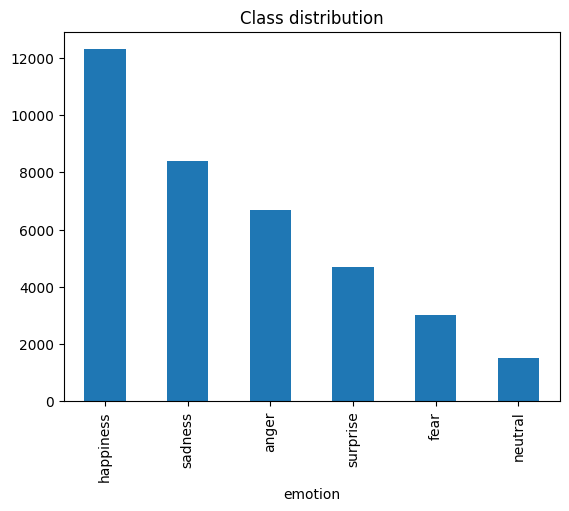

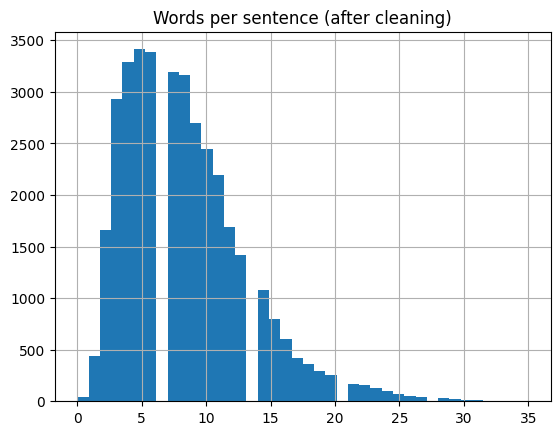

count    36584.000000
mean         8.283239
std          4.745305
min          0.000000
25%          5.000000
50%          7.000000
75%         11.000000
max         35.000000
Name: n_words, dtype: float64


In [8]:
import matplotlib.pyplot as plt
from collections import Counter

df["emotion"].value_counts().plot(kind="bar", title="Class distribution"); plt.show()

df["n_words"] = df["clean"].str.split().str.len()
df["n_words"].hist(bins=40); plt.title("Words per sentence (after cleaning)"); plt.show()
print(df["n_words"].describe())

In [11]:
for e in EMOTIONS:
    words = " ".join(df.loc[df["emotion"] == e, "clean"]).split()
    print(f"{e:10s}", [w for w, _ in Counter(words).most_common(10)])

happiness  ['feel', 'feeling', 'like', 'im', 'not', 'love', 'time', 'really', 'make', 'get']
sadness    ['feel', 'feeling', 'im', 'like', 'not', 'sorry', 'really', 'time', 'know', 'get']
anger      ['feel', 'feeling', 'not', 'like', 'im', 'dont', 'no', 'people', 'get', 'really']
fear       ['feel', 'feeling', 'im', 'like', 'not', 'little', 'time', 'know', 'afraid', 'scared']
surprise   ['feel', 'not', 'im', 'like', 'know', 'dont', 'feeling', 'would', 'think', 'one']
neutral    ['not', 'like', 'get', 'no', 'dont', 'think', 'one', 'people', 'time', 'would']


## 4. Baseline — Scikit-learn (TF-IDF + Logistic Regression)

              precision    recall  f1-score   support

   happiness       0.90      0.80      0.85      2460
     sadness       0.87      0.78      0.82      1679
       anger       0.71      0.66      0.68      1336
        fear       0.79      0.81      0.80       604
    surprise       0.52      0.59      0.55       939
     neutral       0.15      0.36      0.22       299

    accuracy                           0.73      7317
   macro avg       0.66      0.67      0.65      7317
weighted avg       0.77      0.73      0.74      7317



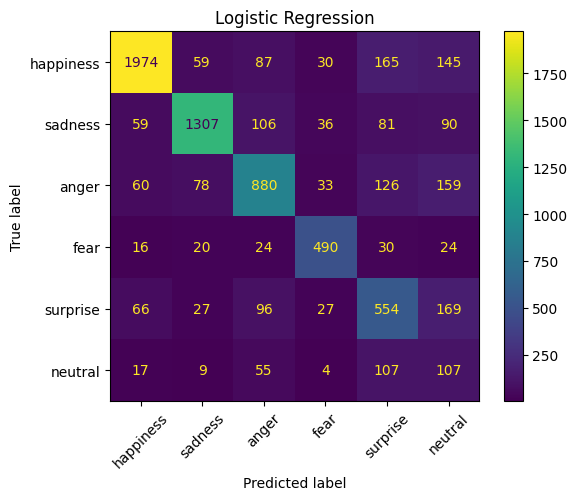

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000)
X_tr = tfidf.fit_transform(train_df["clean"])
X_te = tfidf.transform(test_df["clean"])

lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_tr, train_df["y"])
pred_lr = lr.predict(X_te)

print(classification_report(test_df["y"], pred_lr, target_names=EMOTIONS))
ConfusionMatrixDisplay(confusion_matrix(test_df["y"], pred_lr), display_labels=EMOTIONS).plot(xticks_rotation=45)
plt.title("Logistic Regression"); plt.show()

## 5. LSTM (PyTorch)

In [15]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

vocab = {"<pad>": 0, "<unk>": 1}
for t in train_df["clean"]:
    for w in t.split():
        vocab.setdefault(w, len(vocab))
MAXLEN = 40

def encode(texts):
    out = np.zeros((len(texts), MAXLEN), dtype=np.int64)
    for i, t in enumerate(texts):
        ids = [vocab.get(w, 1) for w in t.split()][:MAXLEN]
        out[i, :len(ids)] = ids
    return torch.tensor(out)

def loader(d, shuffle):
    return DataLoader(TensorDataset(encode(d["clean"].tolist()), torch.tensor(d["y"].values)),
                      batch_size=64, shuffle=shuffle)

tr_dl, va_dl, te_dl = loader(train_df, True), loader(val_df, False), loader(test_df, False)

device: cuda


In [16]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, emb=128, hid=128):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc   = nn.Linear(hid * 2, n_classes)

    def forward(self, x):
        _, (h, _) = self.lstm(self.emb(x))
        return self.fc(self.drop(torch.cat([h[-2], h[-1]], dim=1)))

lstm = LSTMClassifier(len(vocab), len(EMOTIONS)).to(device)
opt, loss_fn = torch.optim.Adam(lstm.parameters(), lr=1e-3), nn.CrossEntropyLoss()

for epoch in range(5):
    lstm.train(); tot = 0
    for xb, yb in tr_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(lstm(xb), yb)
        loss.backward(); opt.step()
        tot += loss.item()
    lstm.eval(); correct = 0
    with torch.no_grad():
        for xb, yb in va_dl:
            correct += (lstm(xb.to(device)).argmax(1).cpu() == yb).sum().item()
    print(f"epoch {epoch+1}  loss={tot/len(tr_dl):.3f}  val_acc={correct/len(val_df):.3f}")

epoch 1  loss=1.354  val_acc=0.595
epoch 2  loss=0.830  val_acc=0.697
epoch 3  loss=0.614  val_acc=0.726
epoch 4  loss=0.489  val_acc=0.729
epoch 5  loss=0.389  val_acc=0.722


              precision    recall  f1-score   support

   happiness       0.79      0.87      0.83      2460
     sadness       0.75      0.84      0.79      1679
       anger       0.68      0.63      0.66      1336
        fear       0.83      0.71      0.77       604
    surprise       0.55      0.48      0.51       939
     neutral       0.16      0.09      0.11       299

    accuracy                           0.73      7317
   macro avg       0.63      0.60      0.61      7317
weighted avg       0.71      0.73      0.72      7317



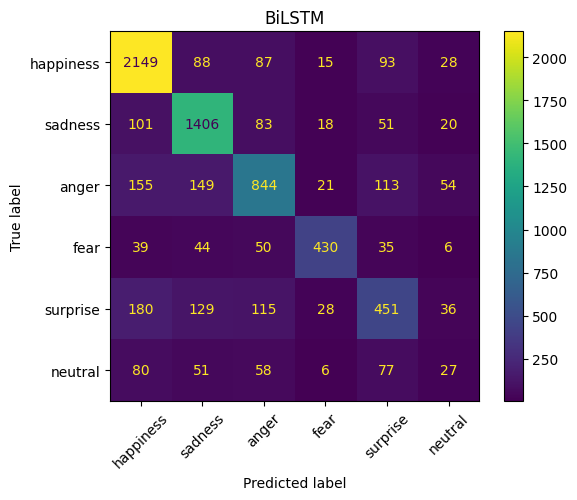

In [17]:
lstm.eval(); pred_lstm = []
with torch.no_grad():
    for xb, _ in te_dl:
        pred_lstm += lstm(xb.to(device)).argmax(1).cpu().tolist()

print(classification_report(test_df["y"], pred_lstm, target_names=EMOTIONS))
ConfusionMatrixDisplay(confusion_matrix(test_df["y"], pred_lstm), display_labels=EMOTIONS).plot(xticks_rotation=45)
plt.title("BiLSTM"); plt.show()

## 6. BERT (fine-tuned)

In [18]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

bert_name = "bert-base-uncased"
tok  = AutoTokenizer.from_pretrained(bert_name)
bert = AutoModelForSequenceClassification.from_pretrained(
    bert_name, num_labels=len(EMOTIONS), id2label=id2label, label2id=label2id
).to(device)

def bert_loader(d, shuffle):
    enc = tok(d["text"].tolist(), padding=True, truncation=True, max_length=64, return_tensors="pt")  # raw text
    return DataLoader(TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(d["y"].values)),
                      batch_size=32, shuffle=shuffle, pin_memory=True)

btr, bva, bte = bert_loader(train_df, True), bert_loader(val_df, False), bert_loader(test_df, False)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [19]:
from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm

# PENALTY #2 - weighted loss: rare classes count more, neutral gets an extra 0.5x penalty
NEUTRAL_WEIGHT = 0.5
counts = train_df["y"].value_counts().sort_index().values
w = torch.tensor(len(train_df) / (len(counts) * counts), dtype=torch.float)
w[label2id["neutral"]] *= NEUTRAL_WEIGHT
print("class weights:", dict(zip(EMOTIONS, w.round(decimals=2).tolist())))
loss_fn = torch.nn.CrossEntropyLoss(weight=w.to(device))

opt = torch.optim.AdamW(bert.parameters(), lr=2e-5)
scaler = GradScaler("cuda")          # mixed precision (fp16) = ~2x faster on T4

for epoch in range(2):
    bert.train()
    for ids, mask, yb in tqdm(btr, desc=f"epoch {epoch+1}"):
        opt.zero_grad()
        with autocast("cuda", dtype=torch.float16):
            logits = bert(input_ids=ids.to(device, non_blocking=True),
                          attention_mask=mask.to(device, non_blocking=True)).logits
        loss = loss_fn(logits.float(), yb.to(device, non_blocking=True))
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()

    bert.eval(); correct = 0
    with torch.no_grad(), autocast("cuda", dtype=torch.float16):
        for ids, mask, yb in bva:
            logits = bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            correct += (logits.argmax(1).cpu() == yb).sum().item()
    print(f"epoch {epoch+1}  val_acc={correct/len(val_df):.3f}")

class weights: {'happiness': 0.5, 'sadness': 0.7300000190734863, 'anger': 0.9100000262260437, 'fear': 2.0199999809265137, 'surprise': 1.2999999523162842, 'neutral': 2.0399999618530273}


epoch 1:   0%|          | 0/824 [00:00<?, ?it/s]

epoch 1  val_acc=0.829


epoch 2:   0%|          | 0/824 [00:00<?, ?it/s]

epoch 2  val_acc=0.828


              precision    recall  f1-score   support

   happiness       0.97      0.85      0.91      2460
     sadness       0.90      0.86      0.88      1679
       anger       0.79      0.76      0.77      1336
        fear       0.78      0.89      0.83       604
    surprise       0.64      0.84      0.73       939
     neutral       0.32      0.36      0.34       299

    accuracy                           0.82      7317
   macro avg       0.73      0.76      0.74      7317
weighted avg       0.83      0.82      0.82      7317



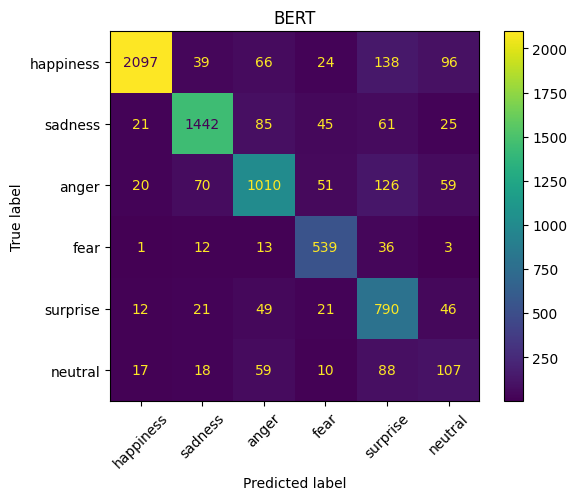

In [20]:
bert.eval(); pred_bert = []
with torch.no_grad():
    for ids, mask, _ in bte:
        pred_bert += bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.argmax(1).cpu().tolist()

print(classification_report(test_df["y"], pred_bert, target_names=EMOTIONS))
ConfusionMatrixDisplay(confusion_matrix(test_df["y"], pred_bert), display_labels=EMOTIONS).plot(xticks_rotation=45)
plt.title("BERT"); plt.show()

## 7. Model comparison & save (model + metrics.json)

Logistic Regression  macro-F1 = 0.654
BiLSTM               macro-F1 = 0.613
BERT                 macro-F1 = 0.742


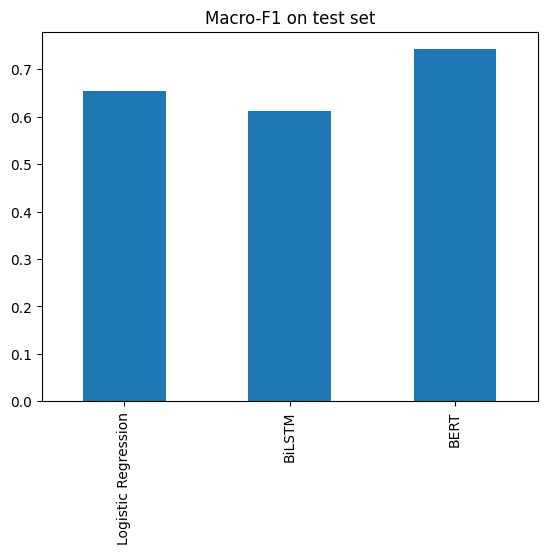

In [21]:
results = {name: f1_score(test_df["y"], p, average="macro")
           for name, p in [("Logistic Regression", pred_lr), ("BiLSTM", pred_lstm), ("BERT", pred_bert)]}
for k, v in results.items():
    print(f"{k:20s} macro-F1 = {v:.3f}")
pd.Series(results).plot(kind="bar", title="Macro-F1 on test set"); plt.show()

In [22]:
# --- Save model + metrics.json (the dashboard reads metrics.json) ---
import json, datetime
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

bert.save_pretrained("emotion_bert")
tok.save_pretrained("emotion_bert")

p, r, f, s = precision_recall_fscore_support(test_df["y"], pred_bert, labels=list(range(len(EMOTIONS))), zero_division=0)
metrics = {
    "classes": EMOTIONS,
    "bert": {
        "accuracy": float(accuracy_score(test_df["y"], pred_bert)),
        "macro_f1": float(f1_score(test_df["y"], pred_bert, average="macro")),
        "per_class": {e: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])}
                      for i, e in enumerate(EMOTIONS)},
        "confusion_matrix": confusion_matrix(test_df["y"], pred_bert).tolist(),
    },
    "models": {k: float(v) for k, v in results.items()},
    "accuracy": {"Logistic Regression": float(accuracy_score(test_df["y"], pred_lr)),
                 "BiLSTM": float(accuracy_score(test_df["y"], pred_lstm)),
                 "BERT": float(accuracy_score(test_df["y"], pred_bert))},
    "train_size": int(len(train_df)), "val_size": int(len(val_df)), "test_size": int(len(test_df)),
    "class_counts": {e: int((df["emotion"] == e).sum()) for e in EMOTIONS},
    "neutral_cap": CAP["neutral"], "neutral_loss_weight": NEUTRAL_WEIGHT,
    "base_model": bert_name,
    "trained_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
}
json.dump(metrics, open("emotion_bert/metrics.json", "w"), indent=2)
print(json.dumps({k: metrics[k] for k in ["models", "accuracy", "class_counts"]}, indent=2))

!cd /content && rm -f emotion_bert.zip && zip -qr emotion_bert.zip emotion_bert
from google.colab import files
files.download("/content/emotion_bert.zip")   # model + metrics.json, ~390 MB

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "models": {
    "Logistic Regression": 0.6536102755947878,
    "BiLSTM": 0.612587277439774,
    "BERT": 0.7420540738749111
  },
  "accuracy": {
    "Logistic Regression": 0.7259805931392648,
    "BiLSTM": 0.7252972529725297,
    "BERT": 0.8179581795817958
  },
  "class_counts": {
    "happiness": 12300,
    "sadness": 8394,
    "anger": 6681,
    "fear": 3022,
    "surprise": 4694,
    "neutral": 1493
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# quick sanity check on new sentences (same norm() as training)
from transformers import pipeline
clf = pipeline("text-classification", model="emotion_bert", tokenizer="emotion_bert", device=0 if device == "cuda" else -1)
for s in ["I got the job, best day ever!", "I miss her so much", "Why would they do this to me?!",
          "I'm scared of what happens next", "Wait, you're here?!", "The meeting is at 3 pm."]:
    print(f"{s:40s} -> {clf(norm(s))[0]}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

I got the job, best day ever!            -> {'label': 'happiness', 'score': 0.9323574304580688}
I miss her so much                       -> {'label': 'sadness', 'score': 0.9829064011573792}
Why would they do this to me?!           -> {'label': 'surprise', 'score': 0.8123515844345093}
I'm scared of what happens next          -> {'label': 'fear', 'score': 0.9951727986335754}
Wait, you're here?!                      -> {'label': 'surprise', 'score': 0.7677444815635681}
The meeting is at 3 pm.                  -> {'label': 'neutral', 'score': 0.7805365920066833}


## 8. Deployment — Flask dashboard (runs locally)

Folder layout on your laptop:

```
emotion_app/
├── app.py
├── index.html
└── emotion_bert/        <- unzip emotion_bert.zip here (includes metrics.json)
```

1. `pip install torch --index-url https://download.pytorch.org/whl/cpu`
2. `pip install flask transformers`
3. `python app.py` → open http://127.0.0.1:5000

In [24]:
!pip -q install onnx onnxruntime
import os, shutil, torch
from huggingface_hub import login, HfApi, hf_hub_download
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from onnxruntime.quantization import quantize_dynamic, QuantType

HF_USER = "akshayaaaa0001"        # <- your Hugging Face username
login()                            # paste a WRITE token from huggingface.co/settings/tokens

SRC = "emotion_bert" if os.path.exists("emotion_bert/config.json") else f"{HF_USER}/emotion-bert"
OUT = "emotion_bert_web"
print("Converting from:", SRC)

model = AutoModelForSequenceClassification.from_pretrained(SRC).float().eval()
tok = AutoTokenizer.from_pretrained(SRC)
shutil.rmtree(OUT, ignore_errors=True)
os.makedirs(f"{OUT}/onnx")
model.config.save_pretrained(OUT)
tok.save_pretrained(OUT)

enc = tok(["i feel happy today", "hello"], padding=True, return_tensors="pt")
names = ["input_ids", "attention_mask", "token_type_ids"]
torch.onnx.export(
    model, tuple(enc[n] for n in names), f"{OUT}/onnx/model.onnx",
    input_names=names, output_names=["logits"],
    dynamic_axes={**{n: {0: "batch", 1: "seq"} for n in names}, "logits": {0: "batch"}},
    opset_version=17, dynamo=False,
)
quantize_dynamic(f"{OUT}/onnx/model.onnx", f"{OUT}/onnx/model_quantized.onnx", weight_type=QuantType.QInt8)
os.remove(f"{OUT}/onnx/model.onnx")

try:
    m = "emotion_bert/metrics.json" if os.path.exists("emotion_bert/metrics.json") else hf_hub_download(SRC, "metrics.json")
    shutil.copy(m, f"{OUT}/metrics.json")
except Exception as e:
    print("No metrics.json found (Accuracy section will be empty):", e)

api = HfApi()
api.create_repo(f"{HF_USER}/emotion-bert-web", exist_ok=True)
api.upload_folder(folder_path=OUT, repo_id=f"{HF_USER}/emotion-bert-web")
print("Done! https://huggingface.co/" + HF_USER + "/emotion-bert-web")

Converting from: emotion_bert


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Done! https://huggingface.co/akshayaaaa0001/emotion-bert-web
